# E-Commerce Order Fulfillment & Returns Analytics
**Dataset:** Olist Brazilian e-commerce marketplace (~99K orders, 2016–2018)

**Goal:** understand delivery performance, fulfillment bottlenecks and return risk, and how they drive customer satisfaction.

**Business questions**
1. How fast and reliable is delivery? Where are orders late?
2. Which regions, sellers and categories cause the most problems?
3. How much does late delivery hurt reviews?
4. Which categories carry the highest return risk?

> The dataset has **no returns table**. *Return risk* is proxied as an order that was **canceled/unavailable** or got a **review score ≤ 2**.

**Notebook outline:** 1. Load · 2. Data quality · 3. Cleaning & feature engineering · 4. KPIs · 5. Delivery analysis · 6. Geography · 7. Reviews vs delay · 8. Categories & return risk · 9. Sellers · 10. Conclusions

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)
RAW = Path("../data/raw") if Path("../data/raw").exists() else Path("data/raw")

## 1. Load data

In [2]:
dates = ["order_purchase_timestamp","order_approved_at","order_delivered_carrier_date",
         "order_delivered_customer_date","order_estimated_delivery_date"]
orders = pd.read_csv(RAW/"olist_orders_dataset.csv", parse_dates=dates)
items  = pd.read_csv(RAW/"olist_order_items_dataset.csv")
pay    = pd.read_csv(RAW/"olist_order_payments_dataset.csv")
rev    = pd.read_csv(RAW/"olist_order_reviews_dataset.csv")
cust   = pd.read_csv(RAW/"olist_customers_dataset.csv")
sell   = pd.read_csv(RAW/"olist_sellers_dataset.csv")
prod   = pd.read_csv(RAW/"olist_products_dataset.csv")
trans  = pd.read_csv(RAW/"product_category_name_translation.csv")

for name, d in dict(orders=orders, items=items, payments=pay, reviews=rev,
                    customers=cust, sellers=sell, products=prod).items():
    print(f"{name:10s} {d.shape[0]:>8,} rows x {d.shape[1]} cols")

orders       99,441 rows x 8 cols
items       112,650 rows x 7 cols
payments    103,886 rows x 5 cols
reviews      99,224 rows x 7 cols
customers    99,441 rows x 5 cols
sellers       3,095 rows x 4 cols
products     32,951 rows x 9 cols


## 2. Data quality checks

In [3]:
print("Order status counts:"); print(orders.order_status.value_counts(), "\n")
print("Missing values in orders:"); print(orders.isna().sum()[lambda s: s>0], "\n")
print("Duplicate order_ids:", orders.order_id.duplicated().sum())
print("Orders with >1 review:", (rev.order_id.value_counts()>1).sum())
print("Orders with >1 payment row:", (pay.order_id.value_counts()>1).sum())
print("Products with missing category:", prod.product_category_name.isna().sum())

Order status counts:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64 

Missing values in orders:
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64 

Duplicate order_ids: 0
Orders with >1 review: 547
Orders with >1 payment row: 2961
Products with missing category: 610


**Findings:** missing delivery dates are almost entirely orders that were never delivered (canceled/shipped/etc.), so they are legitimate nulls rather than errors.
Some orders have several reviews and several payment rows, so these tables must be **aggregated to order level** before joining, otherwise revenue would be double counted.

In [4]:
undelivered = orders[orders.order_delivered_customer_date.isna()].order_status.value_counts()
print("Orders missing delivery date, by status:"); print(undelivered)
delivered_missing = orders[(orders.order_status=="delivered") & orders.order_delivered_customer_date.isna()]
print("\nDelivered but no delivery date:", len(delivered_missing))

Orders missing delivery date, by status:
order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64

Delivered but no delivery date: 8


## 3. Cleaning & feature engineering

In [5]:
# Keep the latest review per order
rev1 = rev.sort_values("review_answer_timestamp").drop_duplicates("order_id", keep="last")

# Aggregate payments and items to order level
pay_o = pay.groupby("order_id").agg(payment_value=("payment_value","sum"),
                                    payment_type=("payment_type","first")).reset_index()
prod = prod.merge(trans, on="product_category_name", how="left")
prod["category"] = prod.product_category_name_english.fillna(prod.product_category_name).fillna("unknown")
items = items.merge(prod[["product_id","category"]], on="product_id", how="left")
item_o = items.groupby("order_id").agg(n_items=("order_item_id","count"), price=("price","sum"),
                                       freight=("freight_value","sum"), seller_id=("seller_id","first"),
                                       category=("category","first")).reset_index()

df = (orders.merge(cust[["customer_id","customer_unique_id","customer_state"]], on="customer_id", how="left")
            .merge(item_o, on="order_id", how="left")
            .merge(pay_o, on="order_id", how="left")
            .merge(rev1[["order_id","review_score"]], on="order_id", how="left")
            .merge(sell[["seller_id","seller_state"]], on="seller_id", how="left"))
assert df.order_id.is_unique and len(df)==len(orders)   # no row duplication from joins
print("Order-level table:", df.shape)

Order-level table: (99441, 19)


In [6]:
df["approval_hrs"]   = (df.order_approved_at - df.order_purchase_timestamp).dt.total_seconds()/3600
df["handling_days"]  = (df.order_delivered_carrier_date - df.order_approved_at).dt.total_seconds()/86400
df["transit_days"]   = (df.order_delivered_customer_date - df.order_delivered_carrier_date).dt.total_seconds()/86400
df["delivery_days"]  = (df.order_delivered_customer_date - df.order_purchase_timestamp).dt.total_seconds()/86400
df["delay_days"]     = (df.order_delivered_customer_date - df.order_estimated_delivery_date).dt.total_seconds()/86400
df["is_late"]        = df.delay_days > 0
df["is_cancelled"]   = df.order_status.isin(["canceled","unavailable"])
df["low_review"]     = df.review_score <= 2
df["return_risk"]    = df.is_cancelled | df.low_review.fillna(False)
df["month"]          = df.order_purchase_timestamp.dt.to_period("M").dt.to_timestamp()
df["same_state"]     = df.customer_state == df.seller_state

deliv = df[(df.order_status=="delivered") & (df.delivery_days>=0)].copy()
print("Delivered orders with valid timestamps:", len(deliv))
deliv[["approval_hrs","handling_days","transit_days","delivery_days","delay_days"]].describe().T

Delivered orders with valid timestamps: 96470


,count,mean,std,min,25%,50%,75%,max
approval_hrs,"96,456.00",10.28,20.54,0.00,0.22,0.34,14.52,741.44
handling_days,"96,455.00",2.80,3.54,-171.22,0.87,1.82,3.57,125.76
transit_days,"96,469.00",9.33,8.76,-16.10,4.10,7.10,12.03,205.19
delivery_days,"96,470.00",12.56,9.55,0.53,6.77,10.22,15.72,209.63
delay_days,"96,470.00",-11.18,10.18,-146.02,-16.24,-11.95,-6.39,188.98


## 4. Headline KPIs

In [7]:
kpi = pd.Series({
    "Total orders": len(df),
    "Revenue (R$, non-canceled)": df.loc[df.order_status!="canceled","payment_value"].sum(),
    "Avg order value (R$)": df.payment_value.mean(),
    "Avg delivery days": deliv.delivery_days.mean(),
    "Median delivery days": deliv.delivery_days.median(),
    "Late delivery %": deliv.is_late.mean()*100,
    "Cancellation %": df.is_cancelled.mean()*100,
    "Avg review score": df.review_score.mean(),
    "Return-risk %": df.return_risk.mean()*100,
})
kpi.to_frame("value")

,value
Total orders,"99,441.00"
"Revenue (R$, non-canceled)","15,865,616.52"
Avg order value (R$),160.99
Avg delivery days,12.56
Median delivery days,10.22
Late delivery %,8.11
Cancellation %,1.24
Avg review score,4.09
Return-risk %,14.84


## 5. Delivery performance

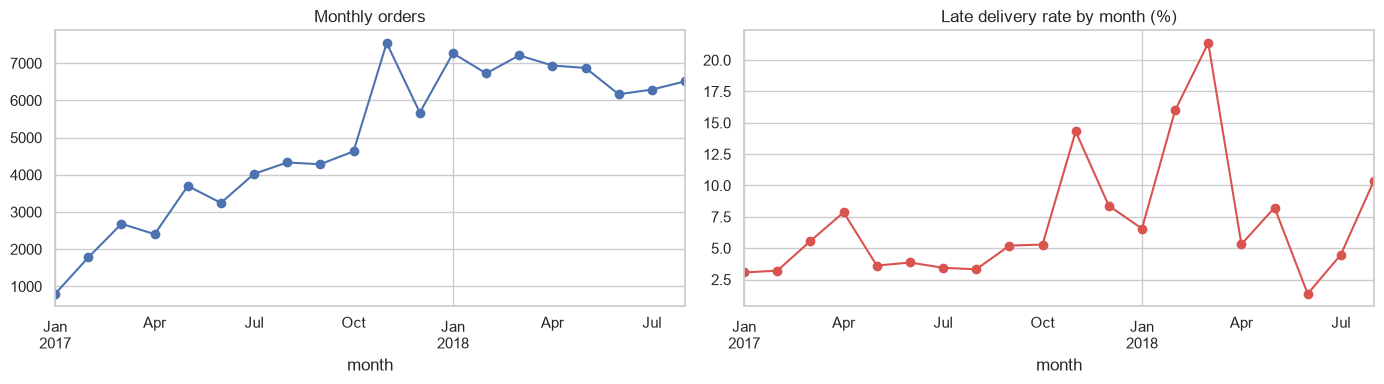

In [8]:
trend = df[(df.month>="2017-01-01") & (df.month<="2018-08-01")]   # drop sparse first/last months
fig, ax = plt.subplots(1, 2, figsize=(14,4))
trend.groupby("month").order_id.count().plot(ax=ax[0], marker="o")
ax[0].set_title("Monthly orders")
(deliv[deliv.month.between("2017-01-01","2018-08-01")].groupby("month").is_late.mean()*100).plot(ax=ax[1], marker="o", color="#d9534f")
ax[1].set_title("Late delivery rate by month (%)")
plt.tight_layout(); plt.show()

Orders grew strongly through 2017 and plateaued in 2018. The late rate spikes to 14% in Nov 2017 (Black Friday surge) and to 16-21% in Feb-Mar 2018 – the logistics network struggles when volume peaks.

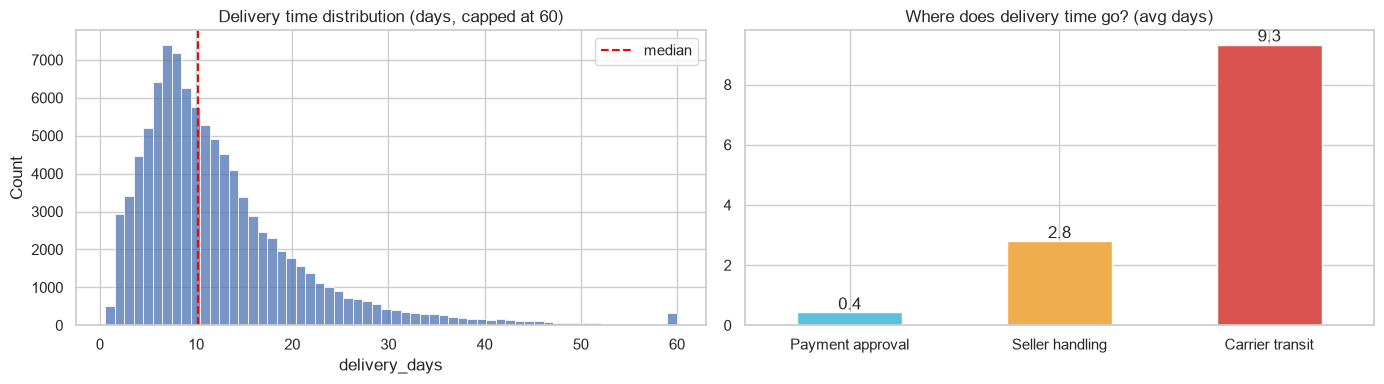

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14,4))
sns.histplot(deliv.delivery_days.clip(upper=60), bins=60, ax=ax[0])
ax[0].axvline(deliv.delivery_days.median(), color="red", ls="--", label="median")
ax[0].set_title("Delivery time distribution (days, capped at 60)"); ax[0].legend()

stages = pd.Series({"Payment approval": deliv.approval_hrs.mean()/24,
                    "Seller handling": deliv.handling_days.mean(),
                    "Carrier transit": deliv.transit_days.mean()})
stages.plot.bar(ax=ax[1], rot=0, color=["#5bc0de","#f0ad4e","#d9534f"])
ax[1].set_title("Where does delivery time go? (avg days)")
for i, v in enumerate(stages): ax[1].text(i, v+0.1, f"{v:.1f}", ha="center")
plt.tight_layout(); plt.show()

**Carrier transit (~9 days) is by far the biggest component** of delivery time, ahead of seller handling (~3 days) and payment approval (<1 day). The distribution is right-skewed, so a long tail of very slow orders pulls the mean (12.6) above the median (10.2).

## 6. Geography

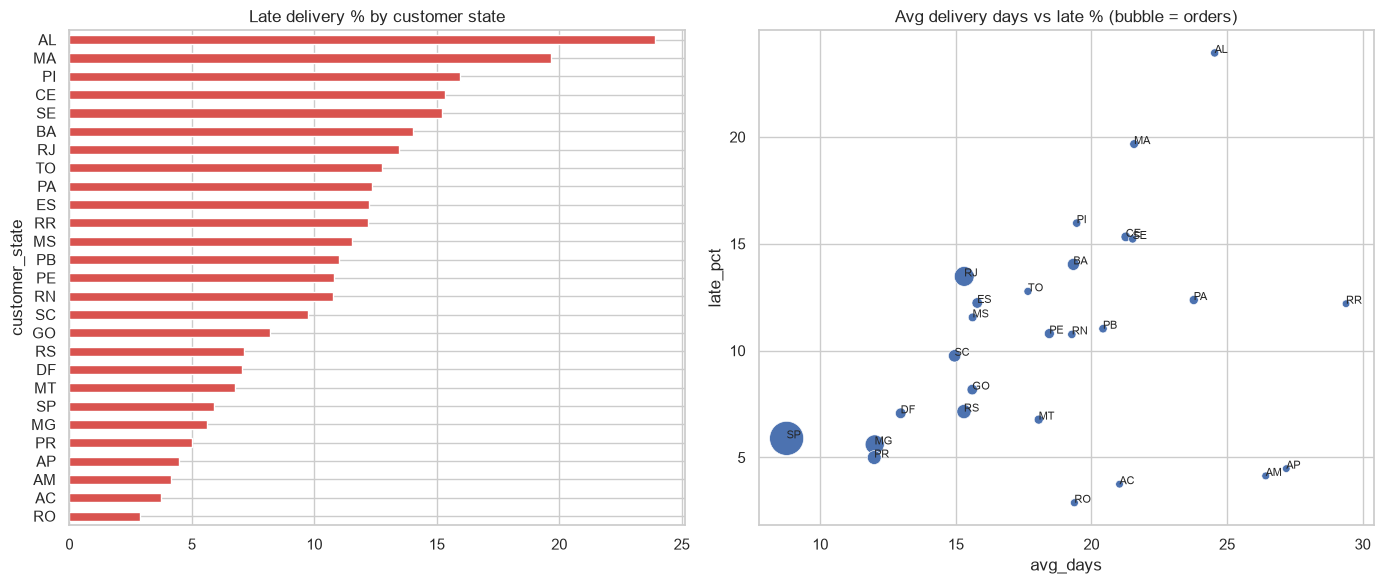

,orders,avg_days,late_pct,avg_review
customer_state,,,,
AL,397,24.54,23.93,3.85
MA,717,21.57,19.67,3.83
PI,476,19.46,15.97,3.99
CE,1279,21.27,15.32,3.94
SE,335,21.52,15.22,3.91
BA,3256,19.34,14.04,3.93


In [10]:
state = deliv.groupby("customer_state").agg(orders=("order_id","count"), avg_days=("delivery_days","mean"),
        late_pct=("is_late", lambda s: s.mean()*100), avg_review=("review_score","mean")).sort_values("late_pct", ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(14,6))
state.sort_values("late_pct").late_pct.plot.barh(ax=ax[0], color="#d9534f")
ax[0].set_title("Late delivery % by customer state")
sns.scatterplot(data=state.reset_index(), x="avg_days", y="late_pct", size="orders", sizes=(30,600), legend=False, ax=ax[1])
for s, r in state.iterrows(): ax[1].annotate(s, (r.avg_days, r.late_pct), fontsize=8)
ax[1].set_title("Avg delivery days vs late % (bubble = orders)")
plt.tight_layout(); plt.show()
state.head(6)

In [11]:
same = deliv.groupby("same_state").delivery_days.agg(["mean","count"])
same.index = ["Different state","Same state"]
same

,mean,count
Different state,15.15,61769
Same state,7.95,34701


The **northeast** (AL, MA, PI, CE, SE) has the worst late rates and 19–25 day average delivery. Orders where seller and customer share a state arrive in ~8 days versus ~15 – about **2x faster** – because 71% of sellers are based in São Paulo.

## 7. Does lateness hurt customer reviews?

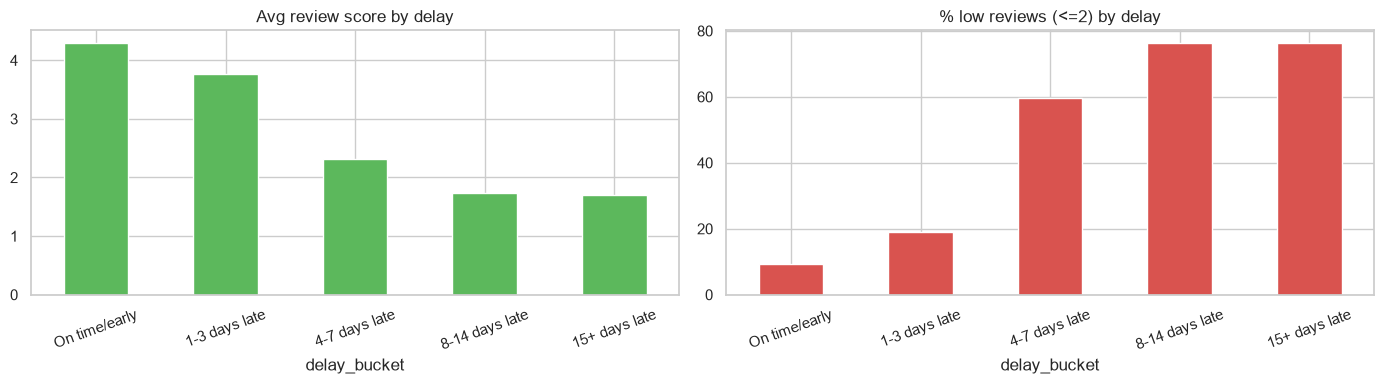

,orders,avg_review,low_review_pct
delay_bucket,,,
On time/early,88644,4.29,9.17
1-3 days late,2662,3.77,18.93
4-7 days late,1819,2.32,59.76
8-14 days late,1790,1.74,76.31
15+ days late,1555,1.71,76.21


In [12]:
bins = [-1000,0,3,7,14,1000]
labels = ["On time/early","1-3 days late","4-7 days late","8-14 days late","15+ days late"]
deliv["delay_bucket"] = pd.cut(deliv.delay_days, bins, labels=labels)
rb = deliv.groupby("delay_bucket", observed=True).agg(orders=("order_id","count"),
        avg_review=("review_score","mean"), low_review_pct=("low_review", lambda s: s.mean()*100))
fig, ax = plt.subplots(1, 2, figsize=(14,4))
rb.avg_review.plot.bar(ax=ax[0], rot=20, color="#5cb85c"); ax[0].set_title("Avg review score by delay")
rb.low_review_pct.plot.bar(ax=ax[1], rot=20, color="#d9534f"); ax[1].set_title("% low reviews (<=2) by delay")
plt.tight_layout(); plt.show()
rb

**Delivery delay is the strongest driver of dissatisfaction.** Average review falls from 4.3 (on time) to 3.8 at just 1–3 days late and to ~1.7 beyond a week; low-review share jumps from ~9% to ~78%.

In [13]:
print("Correlation of review score with:")
print(deliv[["review_score","delay_days","delivery_days","freight","price","handling_days","transit_days"]]
      .corr()["review_score"].drop("review_score").sort_values())

Correlation of review score with:
delivery_days   -0.33
transit_days    -0.30
delay_days      -0.27
handling_days   -0.16
freight         -0.09
price           -0.03
Name: review_score, dtype: float64


## 8. Categories & return risk

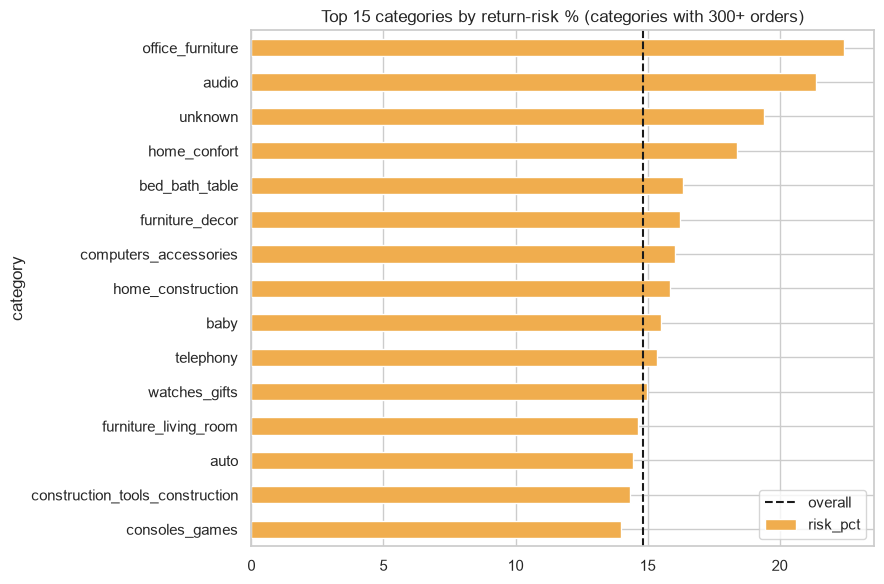

,orders,revenue,risk_pct,avg_review
category,,,,
office_furniture,1265,"273,158.73",22.45,3.62
audio,346,"51,315.60",21.39,3.84
unknown,1416,"179,355.27",19.42,3.93
home_confort,375,"59,092.59",18.40,3.88
bed_bath_table,9311,"1,035,736.39",16.36,3.98
furniture_decor,6355,"733,561.28",16.24,4.02
computers_accessories,6660,"910,590.85",16.04,4.03
home_construction,473,"82,665.41",15.86,4.03


In [14]:
cat = df.groupby("category").agg(orders=("order_id","count"), revenue=("price","sum"),
        risk_pct=("return_risk", lambda s: s.mean()*100), avg_review=("review_score","mean"))
cat = cat[cat.orders>=300].sort_values("risk_pct", ascending=False)
fig, ax = plt.subplots(figsize=(9,6))
cat.head(15).sort_values("risk_pct").risk_pct.plot.barh(ax=ax, color="#f0ad4e")
ax.axvline(df.return_risk.mean()*100, color="k", ls="--", label="overall"); ax.legend()
ax.set_title("Top 15 categories by return-risk % (categories with 300+ orders)")
plt.tight_layout(); plt.show()
cat.head(8)

`office_furniture` and `audio` are well above the overall risk rate. High-volume `bed_bath_table` and `furniture_decor` also sit above average, so they matter most in absolute terms. Bulky categories like furniture are likely hit by both slow shipping and damage.

## 9. Seller performance

621 sellers with 30+ delivered orders; median late rate 6.7%


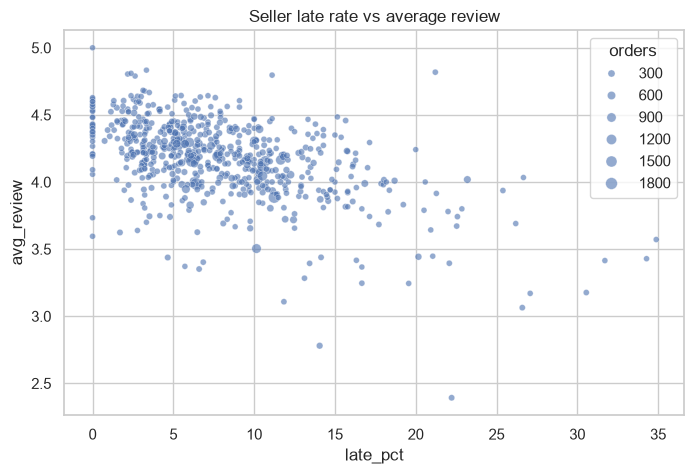

,orders,late_pct,avg_review
seller_id,,,
ede0c03645598cdfc63ca8237acbe73d,43,34.88,3.57
ad781527c93d00d89a11eecd9dcad7c1,35,34.29,3.43
835f0f7810c76831d6c7d24c7a646d4d,41,31.71,3.41
54965bbe3e4f07ae045b90b0b8541f52,72,30.56,3.18
2a1348e9addc1af5aaa619b1a3679d6b,48,27.08,3.17
66e0557ecc2b4dbea057e93f215f68d8,30,26.67,4.03
a49928bcdf77c55c6d6e05e09a9b4ca5,94,26.60,3.06
ef990a83bbea832f36ebe81376335aa8,42,26.19,3.69
beadbee30901a7f61d031b6b686095ad,63,25.40,3.94


In [15]:
sel = deliv.groupby("seller_id").agg(orders=("order_id","count"), late_pct=("is_late", lambda s: s.mean()*100),
        avg_review=("review_score","mean"))
sel = sel[sel.orders>=30]
print(f"{len(sel)} sellers with 30+ delivered orders; median late rate {sel.late_pct.median():.1f}%")
fig, ax = plt.subplots(figsize=(8,5))
sns.scatterplot(data=sel, x="late_pct", y="avg_review", size="orders", alpha=.6, ax=ax)
ax.set_title("Seller late rate vs average review")
plt.show()
sel.sort_values("late_pct", ascending=False).head(10)

## 10. Conclusions & recommendations

**Key findings**
- 8.1% of orders arrive late, but the impact is disproportionate: late orders drive most low reviews.
- Carrier transit is ~75% of delivery time; geography (northeast) and seller location are the main structural drivers.
- Return risk is concentrated in a handful of categories (office furniture, audio, home comfort).
- Only ~3% of customers order again, so a poor first delivery is rarely recovered.

**Recommendations**
1. Set realistic estimated delivery dates for northeast states, or add regional fulfillment hubs.
2. Alert customers proactively before the promised date is missed – the review penalty starts at 1–3 days late.
3. Audit packaging/quality for high-risk categories.
4. Put chronically late sellers on improvement plans and track them with a seller scorecard.

**Limitations:** no true returns data (proxy used); review scores are self-selected; 2016 and late-2018 data are sparse.

**Next steps:** predictive model for late deliveries / bad reviews.